# EDA agent, round r01: real-customer mules at the start of their burst

This round looks for patterns that separate **real-customer mules** (existing customers who start laundering: witting and
unwitting) from normal accounts, and that the 28 store features and the adopted 4-week windows (`roll4`) do not already
capture. The tuned model finds fewer real mules than fake accounts; for real customers the application barely helps
(mainly age), so the activity at the start of the burst is where they can be caught.

Data: `data/v1_full`, accounts opened in months **0–4 only**, read through `amldata`. Month 5 and test months 6–7 are not
touched. A value for week w uses only rows up to that week's cut-off (`open_day + 7w + 6`), and account-weeks the bank
had already closed are dropped.

| § | Question |
|---|---|
| 1 | When do real mules start, and which account-weeks are compared? |
| 2 | Week-level quantities from the raw transactions (definitions) |
| 3 | Do mules forward a matched amount (80–100% of a payment just received)? |
| 4 | Is the largest payment out bigger than anything the account paid before? |
| 5 | Do mules pay the same payee more than once in a week? |
| 6 | Other ideas screened (amounts in, new payers, payers per day, internal and abroad money) |
| 7 | Before the start: is there any signal in the weeks before a real customer starts? |
| 8 | All checks run |
| 9 | Insights |

**How to run.** `PYTHONPATH=src venv/bin/python -c "from features.__main__ import run_notebook;
run_notebook('07_eda_agent_r01.ipynb', 'data/v1_full', None)"`. Figures and CSVs go to `outputs/modelling/eda_agent/r01/`.

## 0. Setup

Paths, the months examined and the helpers. `auc_ci` (from the feature lab) is the rank AUC with a 95% bootstrap interval
over launderers: 0.5 means no signal, missing values rank lowest, NaN under 20 positives. `auc_within` is the same AUC,
but each launderer is compared only with normal accounts of its own stratum (income band, age band, or quintile of a
store feature). Every AUC computed goes through `check`, so section 8 lists all of them.

In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Find the repo root (the folder that holds src/amldata), move there and put src/ on the path, so the notebook runs
# the same from VS Code / Jupyter ("Run All" starts in notebooks/) and from `python -m features ...` (starts at the root).
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import amldata
from amldata import labels
from features import weekly, candidates
from models.feature_lab import auc_ci

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)
RUN = os.path.basename(OUT.rstrip("/"))  # data folder name: reports for runs other than v1_full go in a subfolder
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/eda_agent/r01" + ("" if RUN == "v1_full" else f"/{RUN}")))
TRAIN = (0, 1, 2, 3, 4)                   # months used here; 5 = calibration, 6-7 = test: never read
LAST_WEEK = weekly.LAST_WEEK              # 77: the store's last full week
RELS = (-2, -1, 0, 1)                     # weeks relative to each launderer's start week
SEED = 0
N_NORMAL = 40_000                         # normal accounts per comparison draw (AUC precision rests on the launderers)
REPORT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
print(f"DATA {OUT} | REPORT {REPORT} | months {TRAIN}")

con = amldata.public(OUT)                 # only the `accounts` and `transactions` views
con.execute("PRAGMA memory_limit='6GB'")

CHECKS = []                                # every AUC computed in this notebook (section 8)


def check(section, feature, group, rel, x, y, kind="AUC", note=""):
    a, lo, hi = auc_ci(np.asarray(x, dtype=float), np.asarray(y))
    CHECKS.append(dict(section=section, feature=feature, group=group, rel_week=rel, kind=kind,
                       n_pos=int(np.asarray(y).sum()), auc=a, lo=lo, hi=hi, note=note))
    return a, lo, hi


def placements(x, y):
    """Each positive's place among the negatives (0 below all, 1 above all; ties count half); NaN ranks lowest."""
    x = np.where(np.isnan(x), -np.inf, x)
    neg = np.sort(x[~y])
    return (np.searchsorted(neg, x[y], "left") + np.searchsorted(neg, x[y], "right")) / (2 * len(neg))


def auc_within(section, feature, group, rel, x, y, strata, kind, n_boot=1000):
    """AUC with each positive compared only with negatives of its own stratum; 95% bootstrap over positives."""
    x, y, s = np.asarray(x, dtype=float), np.asarray(y, dtype=bool), np.asarray(strata).astype(str)
    place = np.concatenate([placements(x[s == k], y[s == k]) for k in np.unique(s)
                            if y[s == k].any() and (~y[s == k]).any()])
    a = lo = hi = np.nan
    if len(place) >= 20:
        boots = np.random.default_rng(SEED).choice(place, size=(n_boot, len(place))).mean(axis=1)
        a, (lo, hi) = place.mean(), np.percentile(boots, [2.5, 97.5])
    CHECKS.append(dict(section=section, feature=feature, group=group, rel_week=rel, kind=kind,
                       n_pos=int(y.sum()), auc=a, lo=lo, hi=hi, note=""))
    return a, lo, hi


def fmt(a, lo, hi):
    return "n/a (<20)" if np.isnan(a) else f"{a:.2f} ({lo:.2f}-{hi:.2f})"

DATA data/v1_full | REPORT outputs/modelling/eda_agent/r01 | months (0, 1, 2, 3, 4)


## 1. When real mules start, and which account-weeks are compared

Each launderer's **start week** is the first week whose cut-off reaches its laundering start (`started_by_day`). Fake
accounts start in weeks 8–17; real customers anywhere in weeks 1–75, so the store's weeks 0–77 hold every start.

Launderers are looked at in four weeks: two weeks before the start, the week before, the start week and the week after
(`rel_week` −2, −1, 0, 1). For each group (fake, real, all launderers) and each `rel_week`, 40,000 normal accounts are
drawn, each at one week drawn from that group's start weeks plus the same offset, so both sides sit at the same ages
since opening (cumulative features grow with age: an unmatched draw makes them look different by construction). Weeks after the bank closed an account (`open_by_day = 0`) are dropped.

launderers by type: {'fake': 320, 'unwitting': 69, 'witting': 66} | normal: 164364
start week by type:
           count  min    25%   50%    75%   max
group                                          
fake       320.0  8.0  10.00  13.0  15.00  17.0
unwitting   69.0  1.0  15.00  42.0  64.00  74.0
witting     66.0  1.0  27.25  47.0  61.25  75.0
closed by the bank before or in their start week: 0


rel             -2     -1      0      1
group                                  
fake           320    320    320    316
normal_all   39826  40000  40000  40000
normal_fake  40000  40000  40000  40000
normal_real  39406  40000  40000  40000
unwitting       68     69     69     68
witting         65     66     66     66


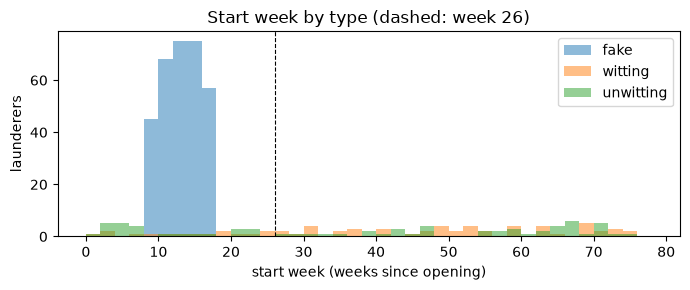

In [2]:
lab = labels(OUT, months=TRAIN, profile=True).set_index("account_id")
start, closed = {}, {}
for w in range(LAST_WEEK + 1):
    lw = labels(OUT, months=TRAIN, weeks_since_open=w)
    for a in lw.loc[lw.started_by_day == 1, "account_id"]:
        start.setdefault(a, w)
    for a in lw.loc[lw.open_by_day == 0, "account_id"]:
        closed.setdefault(a, w)
lab["start_week"] = pd.Series(start)
lab["closed_week"] = pd.Series(closed)
lab["group"] = lab["profile"].fillna("normal")
mules = lab[lab.is_launderer == 1]
print("launderers by type:", mules.group.value_counts().to_dict(), "| normal:", int((lab.is_launderer == 0).sum()))
print("start week by type:")
print(mules.groupby("group").start_week.describe()[["count", "min", "25%", "50%", "75%", "max"]])
print("closed by the bank before or in their start week:", int((mules.closed_week <= mules.start_week).sum()))

rng = np.random.default_rng(SEED)
parts = []
for rel in RELS:
    p = mules.assign(w=mules.start_week + rel, rel=rel)
    parts.append(p[(p.w >= 0) & (p.w <= LAST_WEEK)])
normal = lab[lab.is_launderer == 0]
draw_from = {"all": mules.start_week, "fake": mules.loc[mules.group == "fake", "start_week"],
             "real": mules.loc[mules.group != "fake", "start_week"]}
for name, weeks in draw_from.items():          # one draw per group and week offset, so both sides sit at the same weeks
    for rel in RELS:
        nn = normal.sample(N_NORMAL, random_state=int(rng.integers(1 << 31)))
        nn = nn.assign(w=rng.choice(weeks.to_numpy(), N_NORMAL) + rel, rel=rel, group=f"normal_{name}")
        parts.append(nn[(nn.w >= 0) & (nn.w <= LAST_WEEK)])
picks = pd.concat(parts).reset_index(names="account_id")
picks = picks[picks.closed_week.isna() | (picks.w < picks.closed_week)]           # drop weeks after a closure
picks["w"] = picks.w.astype(int)
picks["pk"] = np.arange(len(picks))
picks = picks.merge(con.execute(f"SELECT account_id, income, customer_age FROM accounts "
                                f"WHERE open_month IN {TRAIN}").df(), on="account_id", validate="m:1")
print(picks.groupby(["group", "rel"], dropna=False).size().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(7, 3))
for g in ("fake", "witting", "unwitting"):
    ax.hist(mules.loc[mules.group == g, "start_week"], bins=range(0, 79, 2), alpha=0.5, label=g)
ax.axvline(26, color="k", lw=0.8, ls="--")
ax.set(xlabel="start week (weeks since opening)", ylabel="launderers", title="Start week by type (dashed: week 26)")
ax.legend()
fig.tight_layout()
fig.savefig(REPORT / "start_weeks.png", dpi=120)

## 2. Week-level quantities from the raw transactions

One DuckDB query computes, for every compared account-week, quantities the store does not hold. Only rows up to the
week's cut-off are read; "this week" means the 7 days ending at the cut-off, "before" means every earlier row of the account.
Card spending (`CARD_MERCHANTS`, one row per week) is left out of the payment-out quantities.

| quantity | definition |
|---|---|
| `match_share` | money paid out within 24 h of the latest payment in **and** worth 80–100% of that payment, over the week's money in |
| `n_match` | the number of such payments out |
| `max_out_vs_hist` | largest payment out this week / largest payment out in all earlier weeks |
| `rep_payee_max` | the most payments to one payee (not cash, not card) this week |
| `max_in_vs_hist` | largest payment in this week / largest payment in in all earlier weeks |
| `newpayer_money_share` | money in from payers seen for the first time / the week's money in |
| `payers_1day` | the most distinct payers (not cash) on one day of the week |
| `internal_in_share` | money in from accounts inside the bank (`A*`) / money in |
| `internal_out_share_wk` | money out to accounts inside the bank / money out (the store keeps only a cumulative version) |
| `abroad_in_share` | money in from a sender outside the UK / money in |

The 80–100% band was fixed before looking (a mule who keeps a cut forwards most, not all, of what arrives).
The store and `roll4` columns are then joined to the same rows, and so is `self4` (a tried candidate, for comparison).

In [3]:
con.register("picks", picks[["pk", "account_id", "w"]])
SQL = """
WITH p AS (SELECT p.pk, p.account_id, a.open_day + 7 * p.w AS wstart, a.open_day + 7 * p.w + 6 AS cut
           FROM picks p JOIN accounts a USING (account_id)),
t AS (SELECT p.pk, x.direction AS dir, x.counterparty_id AS cp, x.amount, x.day, x.sender_bank_location AS sloc,
             x.day >= p.wstart AS this_wk,
             x.day * 86400 + CAST(substr(x.time, 1, 2) AS INT) * 3600 + CAST(substr(x.time, 4, 2) AS INT) * 60
                 + CAST(substr(x.time, 7, 2) AS INT) AS ts,
             row_number() OVER (PARTITION BY p.pk, x.direction, x.counterparty_id ORDER BY x.day, x.time, x.txn_id) AS nth
      FROM transactions x JOIN p USING (account_id)
      WHERE x.day <= p.cut),                                    -- no peeking: rows up to the week's cut-off only
wk AS (SELECT pk,
              sum(amount) FILTER (WHERE dir = 'in')                                         AS money_in,
              sum(amount) FILTER (WHERE dir = 'out')                                        AS money_out,
              max(amount) FILTER (WHERE dir = 'in')                                         AS max_in,
              max(amount) FILTER (WHERE dir = 'out' AND cp <> 'CARD_MERCHANTS')             AS max_out,
              sum(amount) FILTER (WHERE dir = 'in' AND cp LIKE 'A%')                        AS internal_in,
              sum(amount) FILTER (WHERE dir = 'out' AND cp LIKE 'A%')                       AS internal_out,
              sum(amount) FILTER (WHERE dir = 'in' AND sloc <> 'UK')                        AS abroad_in,
              sum(amount) FILTER (WHERE dir = 'in' AND cp <> 'CASH' AND nth = 1)            AS newpayer_in
       FROM t WHERE this_wk GROUP BY pk),
hist AS (SELECT pk, max(amount) FILTER (WHERE dir = 'in')                                   AS max_in_before,
                    max(amount) FILTER (WHERE dir = 'out' AND cp <> 'CARD_MERCHANTS')       AS max_out_before
         FROM t WHERE NOT this_wk GROUP BY pk),
rep AS (SELECT pk, max(n) AS rep_payee_max FROM (
            SELECT pk, cp, count(*) AS n FROM t
            WHERE this_wk AND dir = 'out' AND cp NOT IN ('CASH', 'CARD_MERCHANTS') GROUP BY pk, cp) GROUP BY pk),
day1 AS (SELECT pk, max(n) AS payers_1day FROM (
            SELECT pk, day, count(DISTINCT cp) AS n FROM t
            WHERE this_wk AND dir = 'in' AND cp <> 'CASH' GROUP BY pk, day) GROUP BY pk),
ins AS (SELECT pk, ts, amount AS in_amount FROM t WHERE dir = 'in'),
outs AS (SELECT o.pk, o.amount, o.ts - i.ts AS delay, i.in_amount       -- each payment out, with the latest payment in
         FROM (SELECT pk, ts, amount FROM t WHERE this_wk AND dir = 'out' AND cp <> 'CARD_MERCHANTS') o
         ASOF LEFT JOIN ins i ON o.pk = i.pk AND o.ts >= i.ts),
mt AS (SELECT pk,
              count(*) FILTER (WHERE delay <= 86400 AND amount BETWEEN 0.8 * in_amount AND in_amount)    AS n_match,
              sum(amount) FILTER (WHERE delay <= 86400 AND amount BETWEEN 0.8 * in_amount AND in_amount) AS match_money
       FROM outs GROUP BY pk)
SELECT p.pk, wk.* EXCLUDE (pk), hist.* EXCLUDE (pk), rep.rep_payee_max, day1.payers_1day, mt.n_match, mt.match_money
FROM p LEFT JOIN wk USING (pk) LEFT JOIN hist USING (pk) LEFT JOIN rep USING (pk) LEFT JOIN day1 USING (pk)
       LEFT JOIN mt USING (pk)"""
raw = con.execute(SQL).df()

d = picks.merge(raw, on="pk", validate="1:1")
for c in ("rep_payee_max", "payers_1day", "n_match"):
    d[c] = d[c].fillna(0)
share = lambda num, den: d[num].fillna(0) / d[den]                   # NaN when the week has no money in (out)
d["match_share"] = share("match_money", "money_in")
d["max_out_vs_hist"] = d.max_out / d.max_out_before
d["max_in_vs_hist"] = d.max_in / d.max_in_before
d["newpayer_money_share"] = share("newpayer_in", "money_in")
d["internal_in_share"] = share("internal_in", "money_in")
d["internal_out_share_wk"] = share("internal_out", "money_out")
d["abroad_in_share"] = share("abroad_in", "money_in")
CAND = ["match_share", "n_match", "max_out_vs_hist", "rep_payee_max", "max_in_vs_hist", "newpayer_money_share",
        "payers_1day", "internal_in_share", "internal_out_share_wk", "abroad_in_share"]

# store features + roll4 (adopted) + self4 (tried) at the same account-weeks, same and earlier weeks only
store = weekly.load(OUT, weeks=(0, LAST_WEEK), months=TRAIN, columns=weekly.FEATURES)
store, new_cols = candidates.add(store, ["roll4", "self4"])
STORE = [c for c in weekly.FEATURES] + candidates.ADOPTED                 # what the model already has
SELF4 = new_cols["self4"]
store = store.rename(columns={"weeks_since_open": "w"})
d = d.merge(store[["account_id", "w"] + [c for c in STORE + SELF4 if c not in ("weeks_since_open",)]],
            on=["account_id", "w"], how="left", validate="m:1")
del store
d["income_band"] = pd.cut(d.income, [0, 0.35, 0.65, 1], labels=["low (0.1-0.3)", "mid (0.4-0.6)", "high (0.7-0.9)"])
d["age_band"] = np.where(d.customer_age < 30, "under 30", "30+")
print(f"{len(d):,} compared account-weeks; missing share per quantity:")
print(d[CAND].isna().mean().round(3).to_string())

481,045 compared account-weeks; missing share per quantity:
match_share              0.453
n_match                  0.000
max_out_vs_hist          0.024
rep_payee_max            0.000
max_in_vs_hist           0.459
newpayer_money_share     0.453
payers_1day              0.000
internal_in_share        0.453
internal_out_share_wk    0.000
abroad_in_share          0.453


Helper for the sections below: a positive group at one `rel_week` against its matched normal draw.
`all` = every launderer, `real` = witting + unwitting. Fake and real mules can separate in opposite directions, so
each is shown on its own.

In [4]:
GROUPS = {"all": ("fake", "witting", "unwitting"), "fake": ("fake",), "real": ("witting", "unwitting"),
          "witting": ("witting",), "unwitting": ("unwitting",)}
NEG = {"all": "normal_all", "fake": "normal_fake", "real": "normal_real", "witting": "normal_real",
       "unwitting": "normal_real"}


def rows(group, rel):
    """Positives of `group` at `rel_week` and their matched normal draw; y = 1 for the positives."""
    sub = d[(d.group.isin(GROUPS[group]) | (d.group == NEG[group])) & (d.rel == rel)]
    return sub, (sub.group != NEG[group]).to_numpy()


def screen(section, feats, rels=RELS, groups=tuple(GROUPS)):
    out = []
    for g in groups:
        for rel in rels:
            sub, y = rows(g, rel)
            for f in feats:
                a, lo, hi = check(section, f, g, rel, sub[f], y)
                out.append(dict(feature=f, group=g, rel=rel, auc=a, lo=lo, hi=hi))
    return pd.DataFrame(out)


def evidence(section, f, groups=tuple(GROUPS), rels=(0, 1)):
    """AUC per group; inside income bands and age bands; the closest store feature (Spearman on real mules' start
    week + their normal draw) and the AUC inside its quintiles; the AUC inside quintiles of out_1h_share_wk."""
    sub, y = rows("real", 0)
    rho = sub[STORE].corrwith(sub[f], method="spearman").abs().sort_values(ascending=False)
    closest = rho.index[0]
    rho_self4 = sub[SELF4].corrwith(sub[f], method="spearman").abs().max()
    res = []
    for g in groups:
        for rel in rels:
            sub, y = rows(g, rel)
            r = dict(group=g, rel=rel, n_pos=int(y.sum()), auc=fmt(*check(section, f, g, rel, sub[f], y)))
            r["in income bands"] = fmt(*auc_within(section, f, g, rel, sub[f], y, sub.income_band, "AUC in income band"))
            r["in age bands"] = fmt(*auc_within(section, f, g, rel, sub[f], y, sub.age_band, "AUC in age band"))
            for s in dict.fromkeys([closest, "out_1h_share_wk"]):
                q = pd.qcut(sub[s], 5, labels=False, duplicates="drop").fillna(-1)   # missing values: own stratum
                r[f"in quintiles of {s}"] = fmt(*auc_within(section, f, g, rel, sub[f], y, q, f"AUC in quintiles of {s}"))
            res.append(r)
    print(f"{f}: closest store feature {closest} (|Spearman| {rho.iloc[0]:.2f}; next {rho.index[1]} "
          f"{rho.iloc[1]:.2f}; highest with the tried self4 group {rho_self4:.2f})")
    return pd.DataFrame(res), closest, rho.iloc[0]

## 3. Do mules forward a matched amount?

A mule passes on what arrives, keeping at most a small cut. The store's speed shares measure how much money leaves within
1 h / 24 h of the latest payment in, whatever the amounts: a normal account that pays rent the day after payday also
scores high. Here a payment out counts only if it is worth 80–100% of the payment that just came in. The figure shows the
ratio "payment out / latest payment in" for payments out within 24 h, normal accounts vs real mules in their start week.

payments out within 24 h of a payment in, by size relative to that payment (share of each side's payments):
side        normal  real mule, start week
ratio                                    
(0.0, 0.3]   0.599                  0.406
(0.3, 0.5]   0.075                  0.143
(0.5, 0.8]   0.073                  0.113
(0.8, 0.9]   0.018                  0.011
(0.9, 1.0]   0.016                  0.250
(1.0, 1.5]   0.058                  0.036
(1.5, inf]   0.161                  0.041


match_share: closest store feature out_24h_share_wk (|Spearman| 0.19; next out_1h_share_wk 0.14; highest with the tried self4 group 0.09)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of out_24h_share_wk,in quintiles of out_1h_share_wk
0,all,0,455,0.87 (0.85-0.88),0.87 (0.85-0.88),0.87 (0.85-0.88),0.73 (0.71-0.76),0.76 (0.74-0.78)
1,all,1,450,0.83 (0.81-0.85),0.83 (0.82-0.85),0.83 (0.81-0.85),0.73 (0.71-0.75),0.75 (0.73-0.77)
2,fake,0,320,0.87 (0.85-0.88),0.87 (0.85-0.88),0.87 (0.85-0.88),0.72 (0.70-0.75),0.75 (0.73-0.78)
3,fake,1,316,0.83 (0.81-0.85),0.83 (0.81-0.86),0.83 (0.81-0.86),0.73 (0.70-0.76),0.75 (0.73-0.78)
4,real,0,135,0.88 (0.86-0.90),0.88 (0.85-0.90),0.88 (0.85-0.90),0.75 (0.71-0.79),0.78 (0.74-0.82)
5,real,1,134,0.84 (0.81-0.87),0.84 (0.81-0.87),0.84 (0.81-0.87),0.72 (0.69-0.77),0.75 (0.70-0.79)
6,witting,0,66,0.88 (0.85-0.91),0.88 (0.85-0.91),0.88 (0.85-0.91),0.76 (0.70-0.82),0.78 (0.72-0.84)
7,witting,1,66,0.83 (0.79-0.87),0.83 (0.79-0.87),0.83 (0.79-0.87),0.70 (0.64-0.76),0.72 (0.66-0.78)
8,unwitting,0,69,0.87 (0.84-0.90),0.87 (0.84-0.91),0.87 (0.84-0.91),0.75 (0.69-0.80),0.77 (0.71-0.83)
9,unwitting,1,68,0.85 (0.80-0.89),0.85 (0.81-0.89),0.85 (0.80-0.89),0.75 (0.69-0.81),0.77 (0.71-0.83)


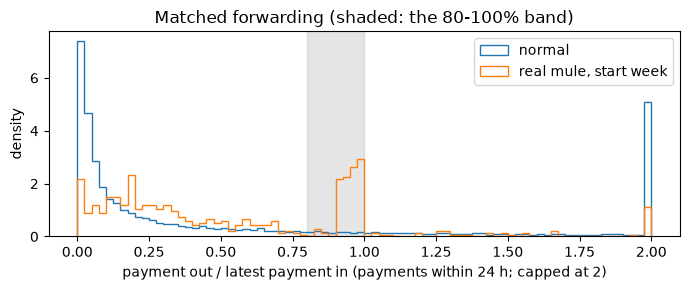

In [5]:
SEC = "3 matched forwarding"
ratio_sql = """
WITH p AS (SELECT p.pk, p.account_id, a.open_day + 7 * p.w AS wstart, a.open_day + 7 * p.w + 6 AS cut
           FROM picks p JOIN accounts a USING (account_id)),
t AS (SELECT p.pk, x.direction AS dir, x.counterparty_id AS cp, x.amount, x.day >= p.wstart AS this_wk,
             x.day * 86400 + CAST(substr(x.time, 1, 2) AS INT) * 3600 + CAST(substr(x.time, 4, 2) AS INT) * 60
                 + CAST(substr(x.time, 7, 2) AS INT) AS ts
      FROM transactions x JOIN p USING (account_id) WHERE x.day <= p.cut AND x.day >= p.wstart - 1),
ins AS (SELECT pk, ts, amount AS in_amount FROM t WHERE dir = 'in')
SELECT o.pk, o.amount / i.in_amount AS ratio
FROM (SELECT pk, ts, amount FROM t WHERE this_wk AND dir = 'out' AND cp <> 'CARD_MERCHANTS') o
ASOF JOIN ins i ON o.pk = i.pk AND o.ts >= i.ts
WHERE o.ts - i.ts <= 86400"""
sel = picks[picks.group.isin(("normal_real",) + GROUPS["real"]) & (picks.rel == 0)]
con.register("picks", sel[["pk", "account_id", "w"]])
ratios = con.execute(ratio_sql).df().merge(sel[["pk", "group"]], on="pk")
ratios["side"] = np.where(ratios.group == "normal_real", "normal", "real mule, start week")
bins = [0, 0.3, 0.5, 0.8, 0.9, 1.0, 1.5, np.inf]
ratio_table = pd.crosstab(pd.cut(ratios.ratio, bins), ratios.side, normalize="columns").round(3)
print("payments out within 24 h of a payment in, by size relative to that payment (share of each side's payments):")
print(ratio_table.to_string())
ratio_table.to_csv(REPORT / "matched_ratio.csv")

fig, ax = plt.subplots(figsize=(7, 3))
for side, grp in ratios.groupby("side"):
    ax.hist(grp.ratio.clip(upper=2), bins=np.linspace(0, 2, 81), density=True, histtype="step", label=side)
ax.axvspan(0.8, 1.0, color="grey", alpha=0.2)
ax.set(xlabel="payment out / latest payment in (payments within 24 h; capped at 2)", ylabel="density",
       title="Matched forwarding (shaded: the 80-100% band)")
ax.legend()
fig.tight_layout()
fig.savefig(REPORT / "matched_ratio.png", dpi=120)

ev_match, close_match, rho_match = evidence(SEC, "match_share")
ev_match

In [6]:
has_match = d.assign(has=d.n_match > 0).groupby(["group", "rel"]).has.mean().unstack()
print("share of compared account-weeks with at least one matched payment out:")
print(has_match.round(3))
ev_nmatch, _, _ = evidence(SEC, "n_match", groups=("real",), rels=(0,))
ev_nmatch

share of compared account-weeks with at least one matched payment out:
rel             -2     -1      0      1
group                                  
fake         0.009  0.006  0.525  0.528
normal_all   0.013  0.013  0.012  0.012
normal_fake  0.012  0.011  0.013  0.012
normal_real  0.012  0.013  0.013  0.013
unwitting    0.029    0.0  0.565  0.559
witting      0.015   0.03  0.591   0.47


n_match: closest store feature out_24h_share_wk (|Spearman| 0.19; next n_in_wk 0.14; highest with the tried self4 group 0.09)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of out_24h_share_wk,in quintiles of out_1h_share_wk
0,real,0,135,0.78 (0.75-0.82),0.78 (0.74-0.82),0.78 (0.74-0.82),0.77 (0.72-0.81),0.78 (0.74-0.82)


## 4. Is the largest payment out bigger than anything the account paid before?

Real customers have months of history before they start, so the size of a payment out can be compared with the account's
own past. `max_out_vs_hist` uses single payments (raw rows, card left out); `max_out_vs_hist_store` is the same idea from
store columns only (this week's `max_out_wk` over the largest earlier `max_out_wk`, which includes the weekly card row).

In [7]:
SEC = "4 largest out vs own history"
st = weekly.load(OUT, weeks=(0, LAST_WEEK), months=TRAIN, columns=["max_out_wk"])
prev = st.groupby("account_id", sort=False).max_out_wk.cummax().groupby(st.account_id.to_numpy(), sort=False).shift(1)
st["max_out_vs_hist_store"] = st.max_out_wk / prev.where(prev > 0)
d = d.merge(st[["account_id", "weeks_since_open", "max_out_vs_hist_store"]].rename(columns={"weeks_since_open": "w"}),
            on=["account_id", "w"], how="left", validate="m:1")
del st
ev_maxout, close_maxout, rho_maxout = evidence(SEC, "max_out_vs_hist")
ev_maxout

max_out_vs_hist: closest store feature money_out_wk (|Spearman| 0.48; next self_vs_past_rows 0.32; highest with the tried self4 group 0.33)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of money_out_wk,in quintiles of out_1h_share_wk
0,all,0,455,0.84 (0.82-0.86),0.84 (0.81-0.86),0.84 (0.82-0.86),0.77 (0.74-0.79),0.84 (0.82-0.86)
1,all,1,450,0.74 (0.72-0.77),0.74 (0.71-0.76),0.74 (0.72-0.77),0.63 (0.60-0.66),0.74 (0.72-0.77)
2,fake,0,320,0.85 (0.83-0.87),0.85 (0.82-0.87),0.85 (0.82-0.87),0.77 (0.74-0.80),0.85 (0.82-0.87)
3,fake,1,316,0.73 (0.70-0.75),0.72 (0.69-0.75),0.73 (0.70-0.76),0.60 (0.57-0.64),0.73 (0.70-0.75)
4,real,0,135,0.81 (0.77-0.86),0.81 (0.77-0.85),0.81 (0.77-0.86),0.77 (0.72-0.81),0.81 (0.77-0.86)
5,real,1,134,0.79 (0.74-0.83),0.79 (0.74-0.83),0.79 (0.75-0.83),0.70 (0.66-0.75),0.79 (0.74-0.83)
6,witting,0,66,0.83 (0.77-0.88),0.83 (0.77-0.88),0.83 (0.77-0.88),0.78 (0.72-0.84),0.83 (0.77-0.88)
7,witting,1,66,0.80 (0.74-0.85),0.80 (0.74-0.86),0.80 (0.74-0.86),0.73 (0.67-0.79),0.80 (0.74-0.85)
8,unwitting,0,69,0.80 (0.72-0.86),0.80 (0.72-0.86),0.80 (0.73-0.86),0.75 (0.67-0.82),0.80 (0.73-0.87)
9,unwitting,1,68,0.77 (0.71-0.83),0.77 (0.71-0.83),0.77 (0.71-0.83),0.68 (0.61-0.74),0.77 (0.71-0.83)


In [8]:
ev_maxout_store, close_maxout_store, rho_maxout_store = evidence(SEC, "max_out_vs_hist_store", groups=("real",), rels=(0,))
ev_maxout_store

max_out_vs_hist_store: closest store feature max_out_wk (|Spearman| 0.51; next card_items_wk 0.43; highest with the tried self4 group 0.27)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of max_out_wk,in quintiles of out_1h_share_wk
0,real,0,135,0.79 (0.75-0.84),0.79 (0.74-0.83),0.79 (0.75-0.84),0.74 (0.68-0.79),0.79 (0.75-0.83)


## 5. Do mules pay the same payee more than once in a week?

Several real mules' bursts show two or more payments to one onward account within days. Before trusting a pattern with so
few normal look-alikes, this section counts it over **every** account-week of months 0–4 (weeks 0–77), not just the
compared sample: how many normal accounts ever pay one payee (not cash, not card) twice in one week, and in which week
relative to the start the launderers do it.

account-weeks (months 0-4, weeks 0-77) with 2+ payments to one payee: 691 of about 12,855,882
accounts with any such week, by type: {'fake': 281, 'normal': 2, 'unwitting': 56, 'witting': 53} | accounts per type: {'normal': 164364, 'fake': 320, 'unwitting': 69, 'witting': 66}
launderers' repeat-payee weeks relative to their start week:
rel
0.0    283
1.0    259
2.0    145
3.0      2
first repeat-payee week relative to the start, real mules: {0.0: 79, 1.0: 25, 2.0: 5}
share of each type with a repeat-payee week in weeks 0-26: {'fake': 0.878, 'normal': 0.0, 'unwitting': 0.319, 'witting': 0.167}


rep_payee_max: closest store feature n_payees_wk (|Spearman| 0.32; next n_out_wk 0.31; highest with the tried self4 group 0.09)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of n_payees_wk,in quintiles of out_1h_share_wk
0,all,0,455,0.81 (0.79-0.83),0.81 (0.79-0.83),0.81 (0.79-0.83),0.81 (0.78-0.83),0.81 (0.79-0.83)
1,all,1,450,0.79 (0.77-0.81),0.79 (0.77-0.81),0.79 (0.77-0.81),0.79 (0.77-0.81),0.79 (0.77-0.82)
2,fake,0,320,0.82 (0.79-0.85),0.82 (0.79-0.85),0.82 (0.80-0.85),0.82 (0.79-0.84),0.82 (0.80-0.85)
3,fake,1,316,0.79 (0.76-0.82),0.79 (0.76-0.82),0.79 (0.76-0.82),0.79 (0.76-0.81),0.79 (0.76-0.82)
4,real,0,135,0.79 (0.75-0.83),0.79 (0.74-0.83),0.79 (0.74-0.83),0.79 (0.74-0.83),0.79 (0.75-0.83)
5,real,1,134,0.79 (0.75-0.83),0.79 (0.76-0.84),0.79 (0.75-0.84),0.79 (0.75-0.83),0.79 (0.75-0.83)
6,witting,0,66,0.78 (0.72-0.83),0.78 (0.72-0.84),0.78 (0.72-0.84),0.78 (0.72-0.84),0.78 (0.72-0.84)
7,witting,1,66,0.80 (0.74-0.85),0.80 (0.74-0.86),0.80 (0.75-0.85),0.80 (0.74-0.85),0.80 (0.75-0.86)
8,unwitting,0,69,0.80 (0.73-0.86),0.80 (0.73-0.86),0.80 (0.73-0.86),0.80 (0.73-0.86),0.80 (0.73-0.86)
9,unwitting,1,68,0.79 (0.72-0.84),0.79 (0.73-0.84),0.79 (0.72-0.84),0.78 (0.72-0.85),0.79 (0.73-0.84)


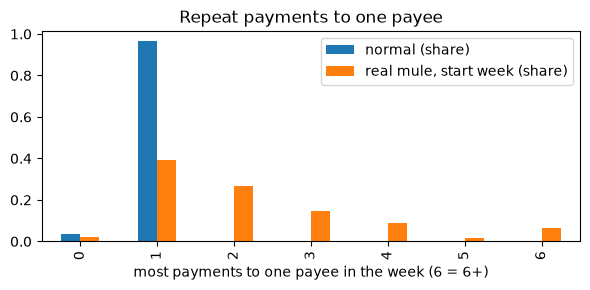

In [9]:
SEC = "5 repeat payee"
rep_all = con.execute(f"""
    WITH t AS (SELECT x.account_id, (x.day - a.open_day) // 7 AS w, x.counterparty_id AS cp
               FROM transactions x JOIN accounts a USING (account_id)
               WHERE a.open_month IN {TRAIN} AND x.direction = 'out' AND x.counterparty_id NOT IN ('CASH', 'CARD_MERCHANTS')
                 AND x.day <= a.open_day + 7 * {LAST_WEEK} + 6)
    SELECT account_id, w, max(n) AS rep FROM (SELECT account_id, w, cp, count(*) AS n FROM t GROUP BY ALL)
    GROUP BY ALL HAVING max(n) >= 2""").df()
rep_all = rep_all.merge(lab[["group", "start_week", "closed_week"]], left_on="account_id", right_index=True)
rep_all = rep_all[rep_all.closed_week.isna() | (rep_all.w < rep_all.closed_week)]
n_weeks = len(lab) * (LAST_WEEK + 1)
rep_all["rel"] = rep_all.w - rep_all.start_week
print(f"account-weeks (months 0-4, weeks 0-{LAST_WEEK}) with 2+ payments to one payee: {len(rep_all):,} of about {n_weeks:,}")
print("accounts with any such week, by type:", rep_all.groupby("group").account_id.nunique().to_dict(),
      "| accounts per type:", lab.group.value_counts().to_dict())
print("launderers' repeat-payee weeks relative to their start week:")
print(rep_all[rep_all.group != "normal"].rel.value_counts().sort_index().to_string())
rep_first = rep_all[rep_all.group != "normal"].groupby("account_id").rel.min()
print("first repeat-payee week relative to the start, real mules:",
      rep_first[rep_first.index.isin(mules.index[mules.group != "fake"])].value_counts().sort_index().to_dict())
print("share of each type with a repeat-payee week in weeks 0-26:",
      (rep_all[rep_all.w <= 26].groupby("group").account_id.nunique() / lab.group.value_counts()).round(3).to_dict())

fig, ax = plt.subplots(figsize=(6, 3))
real_s0 = d[d.group.isin(GROUPS["real"]) & (d.rel == 0)].rep_payee_max.clip(upper=6).value_counts().sort_index()
norm_r = d[(d.group == "normal_real") & (d.rel == 0)].rep_payee_max.clip(upper=6).value_counts().sort_index()
pd.DataFrame({"normal (share)": norm_r / norm_r.sum(), "real mule, start week (share)": real_s0 / real_s0.sum()}).plot.bar(ax=ax)
ax.set(xlabel="most payments to one payee in the week (6 = 6+)", title="Repeat payments to one payee")
fig.tight_layout()
fig.savefig(REPORT / "repeat_payee.png", dpi=120)
ev_rep, close_rep, rho_rep = evidence(SEC, "rep_payee_max")
ev_rep

## 6. Other ideas screened

The remaining quantities from section 2, at the start week and the week after, for every group. Each is then compared
with its closest store feature on real mules: if the AUC inside that feature's quintiles falls to about 0.5, the idea is
the store feature in disguise (redundant).

In [10]:
SEC = "6 other ideas"
OTHER = ["max_in_vs_hist", "newpayer_money_share", "payers_1day", "internal_in_share", "internal_out_share_wk",
         "abroad_in_share"]
scr = screen(SEC, OTHER, rels=(0, 1))
print(scr.assign(auc=scr.apply(lambda r: fmt(r.auc, r.lo, r.hi), axis=1))
      .pivot(index="feature", columns=["group", "rel"], values="auc").to_string())
red = []
for f in OTHER:
    sub, y = rows("real", 0)
    rho = sub[STORE].corrwith(sub[f], method="spearman").abs().sort_values(ascending=False)
    q = pd.qcut(sub[rho.index[0]], 5, labels=False, duplicates="drop").fillna(-1)
    a = auc_within(SEC, f, "real", 0, sub[f], y, q, f"AUC in quintiles of {rho.index[0]}")
    red.append(dict(feature=f, closest=rho.index[0], spearman=round(rho.iloc[0], 2), auc_real_s0=fmt(*auc_ci(sub[f].to_numpy(float), y)),
                    auc_in_quintiles=fmt(*a)))
red = pd.DataFrame(red)
red

group                               all                                fake                                real                             witting                           unwitting                  
rel                                   0                 1                 0                 1                 0                 1                 0                 1                 0                 1
feature                                                                                                                                                                                                  
abroad_in_share          0.73 (nan-nan)  0.70 (0.69-0.71)    0.73 (nan-nan)  0.69 (0.68-0.71)    0.72 (nan-nan)  0.70 (0.68-0.72)    0.72 (nan-nan)  0.71 (0.68-0.72)    0.72 (nan-nan)  0.70 (0.68-0.72)
internal_in_share      0.70 (0.69-0.71)  0.69 (0.68-0.70)  0.71 (0.70-0.72)  0.69 (0.67-0.71)  0.70 (0.69-0.72)  0.69 (0.67-0.72)  0.71 (0.69-0.73)  0.70 (0.66-0.73)  0.69 (0.67-0.71)  0.69 (0

/Users/cheepheng/aml-detection-system/venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,feature,closest,spearman,auc_real_s0,auc_in_quintiles
0,max_in_vs_hist,max_in_wk,0.87,0.76 (0.73-0.78),0.45 (0.40-0.51)
1,newpayer_money_share,new_payer_share_wk,0.99,0.81 (0.80-0.83),0.68 (0.65-0.70)
2,payers_1day,n_payers_wk,0.95,0.80 (0.78-0.83),0.70 (0.66-0.74)
3,internal_in_share,new_payer_share_wk,0.45,0.70 (0.69-0.72),0.47 (0.44-0.50)
4,internal_out_share_wk,internal_out_share_cum,0.21,0.75 (0.70-0.79),0.74 (0.70-0.78)
5,abroad_in_share,n_rows_wk,NaN,0.72 (nan-nan),0.64 (0.63-0.65)


In [11]:
# Among weeks with money in only: are the internal / abroad shares more than "this week has money in"?
for f in ("internal_in_share", "abroad_in_share", "newpayer_money_share"):
    sub, y = rows("real", 0)
    m = sub.money_in.notna().to_numpy()
    print(f, "real mules, start week, weeks with money in only:", fmt(*check(SEC, f, "real", 0, sub.loc[m, f], y[m],
                                                                             note="weeks with money in only")),
          "| share of values > 0, mules / normal:", round((sub.loc[m & y, f] > 0).mean(), 3),
          round((sub.loc[m & ~y, f] > 0).mean(), 3))

internal_in_share real mules, start week, weeks with money in only: 0.46 (0.43-0.48) | share of values > 0, mules / normal: 0.17 0.233
abroad_in_share real mules, start week, weeks with money in only: 0.50 (nan-nan) | share of values > 0, mules / normal: 0.0 0.0
newpayer_money_share real mules, start week, weeks with money in only: 0.66 (0.64-0.69) | share of values > 0, mules / normal: 0.948 0.576


`payers_1day` and `newpayer_money_share` are near-copies of store features (|Spearman| 0.95 and 0.99) but keep some AUC
inside the quintiles. Those store features take few distinct values, so quintiles are coarse; this cell compares
like with like instead: the same number of payers this week, or the same new-payer share rounded to 0.1.

In [12]:
sub, y = rows("real", 0)
exact = {"payers_1day": sub.n_payers_wk.clip(upper=10), "newpayer_money_share": sub.new_payer_share_wk.round(1).fillna(-1)}
for f, strata in exact.items():
    print(f, "real mules, start week, inside exact values of its store twin:",
          fmt(*auc_within(SEC, f, "real", 0, sub[f], y, strata, "AUC in exact values of store twin")))

payers_1day real mules, start week, inside exact values of its store twin: 0.52 (0.48-0.55)


newpayer_money_share real mules, start week, inside exact values of its store twin: 0.50 (0.45-0.55)


The weekly share of money out to accounts inside the bank (`internal_out_share_wk`) keeps its AUC inside the quintiles
of the store's cumulative version, so it gets the full evidence check. It can also be rebuilt from store columns alone
(the change in `internal_out_share_cum x money_out_cum` from last week, over `money_out_wk`); the rebuild is compared
with the raw-row value first.

In [13]:
st = weekly.load(OUT, weeks=(0, LAST_WEEK), months=TRAIN, columns=["money_out_wk", "money_out_cum", "internal_out_share_cum"])
cum_internal = st.internal_out_share_cum.fillna(0) * st.money_out_cum
last_week = cum_internal.groupby(st.account_id.to_numpy(), sort=False).shift(1).fillna(0)
st["internal_out_share_wk_store"] = (cum_internal - last_week) / st.money_out_wk.where(st.money_out_wk > 0)
d = d.merge(st[["account_id", "weeks_since_open", "internal_out_share_wk_store"]].rename(columns={"weeks_since_open": "w"}),
            on=["account_id", "w"], how="left", validate="m:1")
del st
gap = (d.internal_out_share_wk_store - d.internal_out_share_wk).abs()
print(f"store rebuild vs raw rows: largest difference {gap.max():.2e} over {int(gap.notna().sum()):,} account-weeks")
has_int = d.assign(has=d.internal_out_share_wk > 0)[d.rel == 0].groupby("group").has.mean()
print("share of start-week rows with any money out to an account inside the bank:", has_int.round(3).to_dict())
ev_int, close_int, rho_int = evidence(SEC, "internal_out_share_wk")
ev_int

store rebuild vs raw rows: largest difference 7.16e-15 over 481,039 account-weeks
share of start-week rows with any money out to an account inside the bank: {'fake': 0.353, 'normal_all': 0.116, 'normal_fake': 0.11, 'normal_real': 0.128, 'unwitting': 0.609, 'witting': 0.53}


internal_out_share_wk: closest store feature internal_out_share_cum (|Spearman| 0.21; next n_payees_wk 0.18; highest with the tried self4 group 0.10)


,group,rel,n_pos,auc,in income bands,in age bands,in quintiles of internal_out_share_cum,in quintiles of out_1h_share_wk
0,all,0,455,0.66 (0.64-0.68),0.66 (0.63-0.69),0.66 (0.64-0.69),0.66 (0.64-0.68),0.66 (0.64-0.68)
1,all,1,450,0.65 (0.62-0.67),0.65 (0.62-0.67),0.65 (0.62-0.67),0.64 (0.62-0.66),0.65 (0.62-0.67)
2,fake,0,320,0.63 (0.60-0.65),0.63 (0.60-0.65),0.63 (0.60-0.66),0.62 (0.60-0.65),0.63 (0.60-0.65)
3,fake,1,316,0.61 (0.59-0.64),0.61 (0.59-0.64),0.61 (0.59-0.64),0.61 (0.58-0.63),0.62 (0.59-0.64)
4,real,0,135,0.75 (0.70-0.79),0.75 (0.70-0.79),0.75 (0.70-0.79),0.74 (0.70-0.78),0.74 (0.70-0.79)
5,real,1,134,0.72 (0.68-0.77),0.72 (0.68-0.77),0.72 (0.68-0.77),0.71 (0.67-0.76),0.72 (0.68-0.77)
6,witting,0,66,0.72 (0.65-0.79),0.72 (0.66-0.79),0.72 (0.66-0.79),0.72 (0.65-0.78),0.72 (0.66-0.79)
7,witting,1,66,0.71 (0.64-0.77),0.71 (0.64-0.77),0.71 (0.64-0.77),0.70 (0.64-0.76),0.71 (0.64-0.77)
8,unwitting,0,69,0.77 (0.70-0.83),0.77 (0.70-0.83),0.77 (0.71-0.83),0.76 (0.70-0.82),0.77 (0.70-0.83)
9,unwitting,1,68,0.74 (0.68-0.80),0.74 (0.68-0.80),0.74 (0.68-0.80),0.73 (0.66-0.79),0.74 (0.68-0.80)


## 7. Before the start: any signal in the weeks before a real customer starts?

A signal before the start would let the bank act before the money moves. Real customers are not mules yet then, so this
asks whether their accounts already look different. All candidates, the 28 store features and `roll4` are scored at
`rel_week` −2 and −1, for real mules (and their two types) and for fake accounts (who are mules from opening). With this
many looks, about 5% pass by chance. The Phase 1 report found real mules' cumulative row count higher before the start;
since 65% of real mules are under 30 (vs 27% of normal accounts), that lead is re-tested inside age bands.

In [14]:
SEC = "7 before the start"
pre = screen(SEC, CAND + ["max_out_vs_hist_store"] + STORE, rels=(-2, -1), groups=("fake", "real", "witting", "unwitting"))
pre["passes"] = ((pre.auc - 0.5).abs() >= 0.05) & ((pre.lo > 0.5) | (pre.hi < 0.5))
print(f"looks before the start: {len(pre)}, of which {int(pre.auc.notna().sum())} with 20+ positives; "
      f"passing |AUC-0.5| >= 0.05 with an interval excluding 0.5: {int(pre.passes.sum())} "
      f"(about {0.05 * pre.auc.notna().sum():.0f} expected by chance)")
print(pre[pre.passes].assign(auc=lambda x: x.apply(lambda r: fmt(r.auc, r.lo, r.hi), axis=1))
      [["group", "rel", "feature", "auc"]].sort_values(["group", "feature", "rel"]).to_string(index=False))
pre.to_csv(REPORT / "before_start_screen.csv", index=False)

looks before the start: 376, of which 376 with 20+ positives; passing |AUC-0.5| >= 0.05 with an interval excluding 0.5: 21 (about 19 expected by chance)
    group  rel                feature              auc
     fake   -1             max_out_wk 0.57 (0.54-0.60)
     fake   -2           money_in_4wk 0.57 (0.54-0.60)
     fake   -1           money_in_4wk 0.57 (0.54-0.60)
     fake   -2           money_in_cum 0.57 (0.54-0.60)
     fake   -1           money_in_cum 0.58 (0.55-0.61)
     fake   -2          money_out_4wk 0.56 (0.53-0.59)
     fake   -1          money_out_4wk 0.57 (0.54-0.60)
     fake   -2          money_out_cum 0.56 (0.53-0.59)
     fake   -1          money_out_cum 0.57 (0.54-0.60)
     fake   -1           money_out_wk 0.58 (0.55-0.61)
     fake   -2        passthrough_4wk 0.44 (0.41-0.47)
     real   -2          card_items_wk 0.43 (0.39-0.48)
unwitting   -2        abroad_in_share 0.44 (0.38-0.50)
unwitting   -2      internal_in_share 0.44 (0.37-0.50)
unwitting   -2     new

In [15]:
pre_age = []
for f in ("n_rows_cum", "money_in_cum", "card_items_wk"):
    for rel in (-2, -1):
        sub, y = rows("real", rel)
        pre_age.append(dict(feature=f, rel=rel, auc=fmt(*auc_ci(sub[f].to_numpy(float), y)),
                            in_age_bands=fmt(*auc_within(SEC, f, "real", rel, sub[f], y, sub.age_band, "AUC in age band")),
                            in_income_bands=fmt(*auc_within(SEC, f, "real", rel, sub[f], y, sub.income_band,
                                                            "AUC in income band"))))
pd.DataFrame(pre_age)

,feature,rel,auc,in_age_bands,in_income_bands
0,n_rows_cum,-2,0.50 (0.45-0.55),0.50 (0.46-0.55),0.50 (0.45-0.55)
1,n_rows_cum,-1,0.50 (0.45-0.54),0.50 (0.45-0.55),0.50 (0.45-0.55)
2,money_in_cum,-2,0.48 (0.44-0.53),0.50 (0.46-0.55),0.50 (0.46-0.56)
3,money_in_cum,-1,0.48 (0.43-0.53),0.50 (0.45-0.55),0.50 (0.45-0.55)
4,card_items_wk,-2,0.43 (0.39-0.48),0.45 (0.41-0.50),0.45 (0.41-0.50)
5,card_items_wk,-1,0.48 (0.44-0.53),0.50 (0.45-0.55),0.50 (0.45-0.55)


## 8. All checks run

Every AUC this notebook computed, including those that found nothing: section, quantity, group, week relative to the
start, kind of check (plain AUC, inside income / age bands, inside quintiles of a store feature), positives, AUC and
95% interval (NaN under 20 positives). Saved as `checks.csv`.

In [16]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(REPORT / "checks.csv", index=False)
print(f"checks run: {len(checks)}; with 20+ positives: {int(checks.auc.notna().sum())}")
print(checks.groupby(["section", "kind"]).size().to_string())
with pd.option_context("display.max_rows", None):
    display(checks.round(3)) if "ipykernel" in sys.modules else print(checks.round(3).to_string())

checks run: 669; with 20+ positives: 669
section                       kind                                      
3 matched forwarding          AUC                                            11
                              AUC in age band                                11
                              AUC in income band                             11
                              AUC in quintiles of out_1h_share_wk            11
                              AUC in quintiles of out_24h_share_wk           11
4 largest out vs own history  AUC                                            11
                              AUC in age band                                11
                              AUC in income band                             11
                              AUC in quintiles of max_out_wk                  1
                              AUC in quintiles of money_out_wk               10
                              AUC in quintiles of out_1h_share_wk            11
5 repe

,section,feature,group,rel_week,kind,n_pos,auc,lo,hi,note
0,3 matched forwarding,match_share,all,0,AUC,455,0.868,0.855,0.881,
1,3 matched forwarding,match_share,all,0,AUC in income band,455,0.867,0.855,0.879,
2,3 matched forwarding,match_share,all,0,AUC in age band,455,0.868,0.854,0.881,
3,3 matched forwarding,match_share,all,0,AUC in quintiles of out_24h_share_wk,455,0.733,0.711,0.756,
4,3 matched forwarding,match_share,all,0,AUC in quintiles of out_1h_share_wk,455,0.759,0.736,0.781,
5,3 matched forwarding,match_share,all,1,AUC,450,0.834,0.815,0.851,
6,3 matched forwarding,match_share,all,1,AUC in income band,450,0.834,0.816,0.851,
7,3 matched forwarding,match_share,all,1,AUC in age band,450,0.834,0.814,0.852,
8,3 matched forwarding,match_share,all,1,AUC in quintiles of out_24h_share_wk,450,0.728,0.706,0.752,
9,3 matched forwarding,match_share,all,1,AUC in quintiles of out_1h_share_wk,450,0.751,0.727,0.773,


## 9. Insights

The rows this round adds to `outputs/modelling/eda_agent/insights.csv` (also saved as `insights_r01.csv` here). Every
number is taken from the tables above. The simulator audit (which setting produces each pattern, and whether it is an
artefact) was done after the data work, by reading `configs/sim.yaml` and `src/sim/`; its conclusions are written in
by hand. The repeat-payee pattern is recorded as an artefact so nobody trials it.

Nothing passed before the start for real-customer mules (section 7: about as many passes as chance gives, and the
Phase 1 `n_rows_cum` lead is 0.50 once weeks are matched), so every insight is a start-week signal: it can make the first
flag land in the start week instead of later, but it cannot catch a real customer before the money moves.

Redundant with store features (not proposed): `max_in_vs_hist` (vs `max_in_wk`, AUC 0.45 inside its quintiles),
`internal_in_share` (0.47; 0.46 among weeks with money in), `payers_1day` and `newpayer_money_share` (about 0.5 inside
exact values of `n_payers_wk` / `new_payer_share_wk`). `abroad_in_share` is 0 in every week: no money arrives from
abroad, so its AUC only says whether the week had money in.

In [17]:
def ev(tab, group, rel, col="auc"):
    return tab[(tab.group == group) & (tab.rel == rel)][col].iloc[0]


def groups_text(tab, rel=0):
    return (f"all {ev(tab, 'all', rel)}, fake {ev(tab, 'fake', rel)}, real {ev(tab, 'real', rel)} "
            f"(witting {ev(tab, 'witting', rel)}, unwitting {ev(tab, 'unwitting', rel)})")


def pre_text(f):
    p = pre[(pre.feature == f) & (pre.group == "real") & (pre.rel == -1)].iloc[0]
    return fmt(p.auc, p.lo, p.hi)


q_match, q_maxout, q_int = (f"in quintiles of {c}" for c in (close_match, close_maxout, close_int))
n_rep_normal = rep_all[rep_all.group == "normal"].account_id.nunique()
n_rep_real_s0 = int((rep_first[rep_first.index.isin(mules.index[mules.group != "fake"])] == 0).sum())
rep_any_real = rep_all[rep_all.group.isin(GROUPS["real"])].account_id.nunique()
DATE = "2026-10-27"
rows_out = [
    dict(id="r01-1",
         finding="In the start week and the week after, mules pay out within 24 h an amount worth 80-100% of a payment "
                 "they have just received, which normal accounts rarely do; it works the same for real customers and fakes.",
         evidence=(f"Section 3, match_share at the start week: {groups_text(ev_match)}; week after real {ev(ev_match, 'real', 1)}; "
                   f"real inside income bands {ev(ev_match, 'real', 0, 'in income bands')}, inside age bands "
                   f"{ev(ev_match, 'real', 0, 'in age bands')}; real inside quintiles of {close_match} "
                   f"{ev(ev_match, 'real', 0, q_match)} and of out_1h_share_wk {ev(ev_match, 'real', 0, 'in quintiles of out_1h_share_wk')}; "
                   f"a matched payment occurs in {has_match.loc['normal_real', 0]:.1%} of normal weeks vs "
                   f"{has_match.loc['witting', 0]:.0%} / {has_match.loc['unwitting', 0]:.0%} of witting / unwitting start weeks; "
                   f"week before the start real {pre_text('match_share')}."),
         who="all", before_start="no", closest_store_feature=f"{close_match} (Spearman {rho_match:.2f})",
         sim_setting="laundering.holder_keeps [0, 0.10] (amount in = pieces / (1 - keep) in src/sim/laundering.py) with "
                     "laundering.out_pieces_mean 2.0 and laundering.split_max_n_in 4; normal transfers out are drawn "
                     "independently of money in (src/sim/normal.py)",
         sim_strength="assumption (holder_keeps); modelling (out_pieces_mean, split_max_n_in)",
         artefact="partly: forwarding minus a small commission is documented (Europol/FBI), but the 0-10% cut is an "
                  "assumption and normal accounts never pass on a received amount by design, so the gap is likely wider than in a real bank",
         buildable="raw",
         feature_sketch="match_share_wk = money paid out (not card) within 24 h of the latest payment in and worth 80-100% "
                        "of it / money in this week, plus its 4-week sum version"),
    dict(id="r01-2",
         finding="In the start week, a mule's largest single payment out is bigger than anything the account paid out "
                 "before; it holds for real customers with long normal histories, not only for newly opened fake accounts.",
         evidence=(f"Section 4, max_out_vs_hist (raw rows, card left out) at the start week: {groups_text(ev_maxout)}; "
                   f"week after real {ev(ev_maxout, 'real', 1)}; real inside income bands {ev(ev_maxout, 'real', 0, 'in income bands')}, "
                   f"inside age bands {ev(ev_maxout, 'real', 0, 'in age bands')}, inside quintiles of {close_maxout} "
                   f"{ev(ev_maxout, 'real', 0, q_maxout)}; store-only version real {ev(ev_maxout_store, 'real', 0)}, inside "
                   f"quintiles of {close_maxout_store} {ev(ev_maxout_store, 'real', 0, 'in quintiles of ' + close_maxout_store)}; "
                   f"week before the start real {pre_text('max_out_vs_hist')}."),
         who="all", before_start="no",
         closest_store_feature=f"{close_maxout} (Spearman {rho_maxout:.2f}); store version vs {close_maxout_store} {rho_maxout_store:.2f}",
         sim_setting="laundering.out_transfer_mean 532 x laundering.shapes amount_rel with laundering.piece_sigma 0.6, against "
                     "normal one-off transfers sized from income (normal.non_card_value_weights, normal.amount_sigma 0.6)",
         sim_strength="sourced (out_transfer_mean); samld (amount_rel); modelling (piece_sigma, amount_sigma)",
         artefact="partly: mules moving bigger sums than their usual is real (the bank's R6 'sudden change' rule looks for it), "
                  "but the size of the gap rests on modelling spreads and on normal amounts scaling with income only",
         buildable="store",
         feature_sketch="max_out_vs_hist = max_out_wk / largest max_out_wk in weeks 0..w-1 (NaN until an earlier week has "
                        "money out); a raw version that leaves out the weekly card row was a little stronger"),
    dict(id="r01-3",
         finding="Mules pay the same payee two or more times within one week, from the start week to two weeks after, "
                 "which almost no normal account ever does.",
         evidence=(f"Section 5: over all {len(lab):,} accounts of months 0-4 and weeks 0-{LAST_WEEK}, {n_rep_normal} normal "
                   f"accounts ever have such a week vs {rep_any_real} of {int((mules.group != 'fake').sum())} real mules "
                   f"({n_rep_real_s0} already in the start week) and "
                   f"{rep_all[rep_all.group == 'fake'].account_id.nunique()} of {int((mules.group == 'fake').sum())} fakes; "
                   f"rep_payee_max at the start week {groups_text(ev_rep)}; real inside quintiles of {close_rep} "
                   f"{ev(ev_rep, 'real', 0, 'in quintiles of ' + close_rep)}; week before the start real {pre_text('rep_payee_max')}."),
         who="all", before_start="no", closest_store_feature=f"{close_rep} (Spearman {rho_rep:.2f})",
         sim_setting="src/sim/normal.py generate_normal: every one-off normal transfer goes to a new random payee (ext_ids) "
                     "and Direct Debits / standing orders are monthly; laundering.shapes recipients (1 receiver in 6 of 15 shapes)",
         sim_strength="design (normal payees, no setting); samld (recipients)",
         artefact="yes: real customers often pay the same person or their own savings account several times a week, but the "
                  "simulator never lets a normal account repeat a payee within a week, so this is a near-perfect label here that would not carry over to a real bank",
         buildable="raw",
         feature_sketch="rep_payee_max_wk = most payments to one payee (not cash, not card) this week; do not trial, "
                        "recorded so nobody tries it again"),
    dict(id="r01-4",
         finding="In the start week, real-customer mules send a bigger share of the week's money out to other accounts "
                 "inside the bank than normal accounts do, much more clearly than fakes; the store's cumulative share dilutes it.",
         evidence=(f"Section 6, internal_out_share_wk at the start week: {groups_text(ev_int)}; week after real "
                   f"{ev(ev_int, 'real', 1)}; real inside income bands {ev(ev_int, 'real', 0, 'in income bands')}, inside age "
                   f"bands {ev(ev_int, 'real', 0, 'in age bands')}, inside quintiles of {close_int} {ev(ev_int, 'real', 0, q_int)} "
                   f"and of out_1h_share_wk {ev(ev_int, 'real', 0, 'in quintiles of out_1h_share_wk')}; any internal money out in "
                   f"{has_int['normal_real']:.0%} of normal weeks vs {has_int['witting']:.0%} / {has_int['unwitting']:.0%} of "
                   f"witting / unwitting start weeks; week before the start real {pre_text('internal_out_share_wk')}; "
                   f"rebuilt exactly from store columns (largest difference {gap.max():.0e})."),
         who="real", before_start="no", closest_store_feature=f"{close_int} (Spearman {rho_int:.2f})",
         sim_setting="networks.internal_pieces_share 0.5 and laundering.layered_internal_multiplier 2 (a piece goes to the "
                     "next network member only once it has started, src/sim/laundering.py); chains ordered so money flows to "
                     "members who started earlier (src/sim/accounts.py); normal.internal_share_of_transfers 0.10",
         sim_strength="modelling (internal_pieces_share, layered_internal_multiplier); assumption (internal_share_of_transfers); "
                      "sourced (networks.big_network_share)",
         artefact="partly: mule networks are real (Vocalink) but how many hops stay inside one bank is a modelling value, and "
                  "real mules show it more than fakes because the simulator passes money only to members who started earlier, which favours late-starting real customers",
         buildable="store",
         feature_sketch="internal_out_share_wk = (internal_out_share_cum x money_out_cum - the same product last week) / "
                        "money_out_wk, plus a 4-week version"),
]
COLUMNS = ["id", "round", "date", "finding", "evidence", "who", "before_start", "closest_store_feature", "sim_setting",
           "sim_strength", "artefact", "buildable", "feature_sketch", "status", "trial", "note"]
insights = pd.DataFrame(rows_out).assign(round="r01", date=DATE, status="new", trial=None, note=None)[COLUMNS]
insights.to_csv(REPORT / "insights_r01.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    print(insights[["id", "who", "before_start", "artefact", "buildable"]].to_string(index=False))
    for r in insights.itertuples():
        print(f"\n{r.id}: {r.finding}\n  evidence: {r.evidence}")

   id  who before_start                                                                                                                                                                                                                                                         artefact buildable
r01-1  all           no                                        partly: forwarding minus a small commission is documented (Europol/FBI), but the 0-10% cut is an assumption and normal accounts never pass on a received amount by design, so the gap is likely wider than in a real bank       raw
r01-2  all           no                                                   partly: mules moving bigger sums than their usual is real (the bank's R6 'sudden change' rule looks for it), but the size of the gap rests on modelling spreads and on normal amounts scaling with income only     store
r01-3  all           no       yes: real customers often pay the same person or their own savings account several times a week, 